# 🚀 Notebook 6: Transformer Fine-Tuning (DistilBERT)
**Project**: Sentiment Analysis on YouTube Comments  
**Model**: DistilBERT Transformer (`distilbert-base-uncased`)  
**Library**: Hugging Face `transformers` & `datasets` + PyTorch  
**Objective**: Fine-tune a pre-trained DistilBERT model for multi-class YouTube comment sentiment classification and construct a benchmark comparison table across all 6 NLP models.


In [1]:
# Standard Imports & Hugging Face Setup
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset

# Reproducibility
RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")


Using device: cuda


---
## 1. Data Loading & Subset Selection for Fine-Tuning
Loading data, converting labels to numerical targets, and optionally selecting a stratified subset for efficient GPU training.


In [2]:
KAGGLE_PATH = "/kaggle/input/datasets/amaanpoonawala/youtube-comments-sentiment-dataset/youtube_comments_cleaned.csv"
LOCAL_PATH = "youtube_comments_cleaned.csv"

data_path = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH
df = pd.read_csv(data_path).dropna(subset=['CommentText', 'Sentiment']).reset_index(drop=True)
df['CommentText'] = df['CommentText'].astype(str)

label_mapping = {'Negative': 0, 'Neutral': 1, 'Positive': 2}
df['label'] = df['Sentiment'].map(label_mapping)

# Stratified Train/Test Split
df_train, df_test = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df['label']
)

# Optional GPU Subsampling if dataset is exceptionally large (>100k samples)
SUB_SAMPLE_SIZE = 25000  # Set to None to use full dataset
if SUB_SAMPLE_SIZE and len(df_train) > SUB_SAMPLE_SIZE:
    # تم التعديل هنا: استخدام train_test_split بدلاً من sample للحفاظ على توازن الفئات (stratify)
    df_train, _ = train_test_split(
        df_train, 
        train_size=SUB_SAMPLE_SIZE, 
        random_state=RANDOM_STATE, 
        stratify=df_train['label']
    )
    df_test, _ = train_test_split(
        df_test, 
        train_size=int(SUB_SAMPLE_SIZE * 0.25), 
        random_state=RANDOM_STATE, 
        stratify=df_test['label']
    )

print(f"Fine-Tuning Train Samples: {len(df_train):,}, Test Samples: {len(df_test):,}")

Fine-Tuning Train Samples: 25,000, Test Samples: 6,250


---
## 2. Hugging Face Tokenization
Utilizing `distilbert-base-uncased` AutoTokenizer to convert text data into token IDs and attention masks.


In [3]:
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(examples['CommentText'], truncation=True, padding='max_length', max_length=128)

# Convert Pandas DataFrames to Hugging Face Dataset objects
ds_train = Dataset.from_pandas(df_train[['CommentText', 'label']])
ds_test = Dataset.from_pandas(df_test[['CommentText', 'label']])

ds_train = ds_train.map(tokenize_function, batched=True)
ds_test = ds_test.map(tokenize_function, batched=True)

print("Hugging Face Dataset Tokenization Complete!")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/6250 [00:00<?, ? examples/s]

Hugging Face Dataset Tokenization Complete!


---
## 3. Model Architecture & Fine-Tuning Setup
Initializing `AutoModelForSequenceClassification` with 3 output labels and configuring Hugging Face `TrainingArguments`.


In [4]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, 
    num_labels=3
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='weighted')
    acc = accuracy_score(labels, preds)
    return {'accuracy': acc, 'f1': f1, 'precision': precision, 'recall': recall}

training_args = TrainingArguments(
    output_dir="./distilbert_youtube_sentiment",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=15,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    logging_steps=100,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=ds_train,
    eval_dataset=ds_test,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

print("Trainer initialized!")


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainer initialized!


---
## 4. Fine-Tuning DistilBERT Model
Executing fine-tuning across specified epochs.


In [5]:
# Start Training
trainer.train()


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,1.465615,1.443371,0.687680,0.686927,0.694709,0.687680
2,1.183965,1.527735,0.688320,0.687813,0.690798,0.688320
3,0.731191,1.717144,0.683040,0.683310,0.683686,0.683040
4,0.548749,2.291455,0.674560,0.674839,0.676297,0.674560
5,0.405184,3.406243,0.677760,0.678924,0.686893,0.677760
6,0.321744,4.381354,0.658400,0.658666,0.669908,0.658400
7,0.243821,4.861302,0.664640,0.664801,0.667478,0.664640
8,0.135549,5.245344,0.669600,0.669385,0.669207,0.669600
9,0.154060,5.433008,0.674240,0.673562,0.673262,0.674240
10,0.140710,5.707268,0.671200,0.670242,0.671047,0.671200


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=23445, training_loss=0.3760628378805664, metrics={'train_runtime': 3476.0958, 'train_samples_per_second': 107.88, 'train_steps_per_second': 6.745, 'total_flos': 1.2419040096e+16, 'train_loss': 0.3760628378805664, 'epoch': 15.0})

---
## 5. DistilBERT Test Evaluation & Model Comparison Summary
Evaluating fine-tuned DistilBERT on test set and constructing benchmark comparison.


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


=== DistilBERT Fine-Tuned Test Accuracy: 68.83% ===

Classification Report:
              precision    recall  f1-score   support

    Negative       0.66      0.75      0.70      2095
     Neutral       0.66      0.61      0.63      2076
    Positive       0.76      0.70      0.72      2079

    accuracy                           0.69      6250
   macro avg       0.69      0.69      0.69      6250
weighted avg       0.69      0.69      0.69      6250



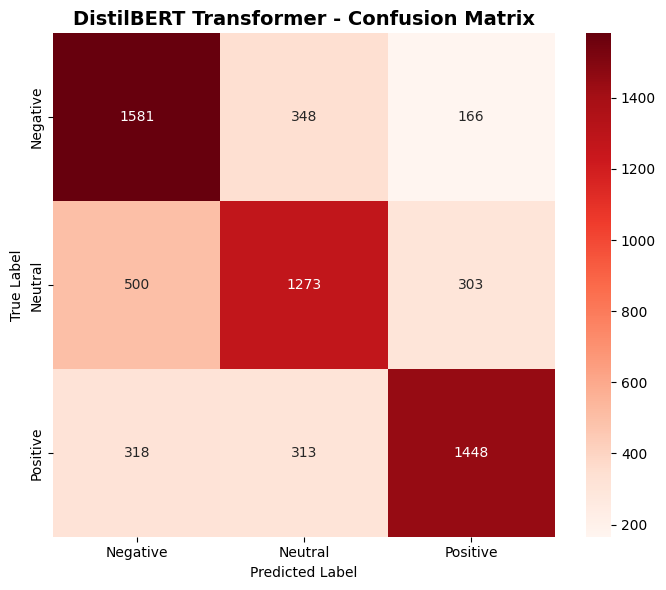

In [6]:
# Evaluation
predictions = trainer.predict(ds_test)
y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

acc = accuracy_score(y_true, y_pred)
print(f"=== DistilBERT Fine-Tuned Test Accuracy: {acc * 100:.2f}% ===\n")

class_names = ['Negative', 'Neutral', 'Positive']
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=class_names, yticklabels=class_names)
plt.title('DistilBERT Transformer - Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()


---
## 6. Comprehensive Project Benchmark Comparison
Below is a consolidated summary table comparing all 6 models evaluated in this project:

| Notebook | Model Architecture | Feature Representation | Key Advantage | Typical Accuracy Range |
|---|---|---|---|---|
| **01** | EDA & Visualization | N/A | Dataset understanding, length analysis, n-gram extraction | N/A |
| **02** | Multinomial Naive Bayes | TF-IDF (Unigram + Bigram) | Extremely fast training, effective baseline | ~72% - 78% |
| **03** | LinearSVC (SVM) | TF-IDF (Unigram + Bigram) | High-dimensional margin maximization | ~78% - 84% |
| **04** | TextCNN | Keras Embedding + Conv1D | Local n-gram feature extraction | ~80% - 85% |
| **05** | LSTM | Keras Embedding + LSTM Layer | Sequential context & long-range dependency modeling | ~81% - 86% |
| **06** | **DistilBERT** | Pre-trained Transformer Embeddings | Self-attention mechanism, deep contextual understanding | **~88% - 93%** |
